<a href="https://colab.research.google.com/github/abhirajadhikary06/Collab-Notebooks/blob/main/ackermann-function.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ackermann Function & Computability Analyzer

Welcome! In this notebook, we will design, implement, and analyze the **Ackermann-Péter Function**, a famous classic example of a system that is computable but not primitive recursive. It serves as a benchmark for understanding recursion, algorithmic complexity, and the limits of practical computation.

---

## 1. Mathematical Definition
For non-negative integers $m$ and $n$, the Ackermann function $A(m, n)$ is defined recursively as follows:

$$
A(m, n) =
\begin{cases}
n + 1 & \text{if } m = 0 \\
A(m - 1, 1) & \text{if } m > 0 \text{ and } n = 0 \\
A(m - 1, A(m, n - 1)) & \text{if } m > 0 \text{ and } n > 0
\end{cases}
$$

### Why is it special?
- **Extreme Growth Rate:** While functions like $2^n$ or $n!$ grow incredibly fast, the Ackermann function grows much faster than any primitive recursive function (such as addition, multiplication, exponentiation, or tower of powers).
- **Computability Theory:** It proved that there are functions that can be computed by a computer program (using general recursion/loops) but cannot be defined using only simple nested loops of predetermined length (primitive recursion).

---

## 2. Our Implementation Blueprint
We will build this application in modular parts:

1. **The Core Recursion Engine:** A Python implementation of $A(m, n)$ enhanced with metrics tracking (execution time, total recursive calls, and peak stack depth).
2. **The Metrics Evaluator & Tabulator:** Running a controlled sweep over safe inputs (e.g., $m \le 3$, $n \le 4$) to compile results into a structured format.
3. **Visual Growth Analysis:** Generating plots using Matplotlib and Seaborn to visualize how the number of steps and compute time explode as inputs increase.
4. **Interactive Colab Dashboard:** A user-friendly interactive panel using `ipywidgets` to safely run calculations and view step-by-step logical traces.

## 1. Core Ackermann Engine with Metrics Tracking

Below, we implement the `ackermann` function. We use Python's recursion, but to safely measure the metrics without polluting the recursive parameters, we track them globally (or via a helper class) within a wrapper function `evaluate_ackermann`.

In [1]:
import time
import sys

# Increase recursion depth limit just in case, though deep parameters will still hit limits.
sys.setrecursionlimit(50000)

class AckermannMetrics:
    def __init__(self):
        self.calls = 0
        self.max_depth = 0
        self.current_depth = 0

def _ack_recursive(m, n, metrics):
    metrics.calls += 1
    metrics.current_depth += 1
    if metrics.current_depth > metrics.max_depth:
        metrics.max_depth = metrics.current_depth

    # Base cases and recursive steps as defined mathematically
    if m == 0:
        result = n + 1
    elif m > 0 and n == 0:
        result = _ack_recursive(m - 1, 1, metrics)
    else:
        inner_result = _ack_recursive(m, n - 1, metrics)
        result = _ack_recursive(m - 1, inner_result, metrics)

    metrics.current_depth -= 1
    return result

def evaluate_ackermann(m, n):
    """
    Computes the Ackermann function value A(m, n) while tracking computational resources.
    Returns (result, metrics_dict)
    """
    metrics = AckermannMetrics()
    start_time = time.perf_counter()
    try:
        result = _ack_recursive(m, n, metrics)
    except RecursionError:
        result = "Recursion Depth Exceeded"
    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    return result, {
        "m": m,
        "n": n,
        "result": result,
        "calls": metrics.calls,
        "max_depth": metrics.max_depth,
        "time_seconds": elapsed_time
    }

# Quick test run
res, stats = evaluate_ackermann(3, 2)
print(f"Result: {res}")
print("Stats:", stats)

Result: 29
Stats: {'m': 3, 'n': 2, 'result': 29, 'calls': 541, 'max_depth': 31, 'time_seconds': 0.00013237999996817962}


## 2. Tabular Growth & Computational Metrics Evaluator

Let's systematically execute the Ackermann function over a grid of small inputs:
- $m \in [0, 1, 2, 3]$
- $n \in [0, 1, 2, 3, 4]$

We will accumulate the results and construct a pandas DataFrame to clearly see the trends in final values, call counts, and execution times.

In [2]:
import pandas as pd

# Prepare lists to hold metric data
data_records = []

# Safely run combinations of m and n
for m in range(4): # m = 0, 1, 2, 3
    for n in range(5): # n = 0, 1, 2, 3, 4
        # We avoid running inputs that would freeze Python due to stack limits (e.g., m >= 4 is extremely dangerous)
        _, stats = evaluate_ackermann(m, n)
        data_records.append(stats)

# Create a Pandas DataFrame for structured presentation
df_metrics = pd.DataFrame(data_records)

# Format float values for better presentation
pd.options.display.float_format = '{:,.6f}'.format

# Display the table
display(df_metrics)

,m,n,result,calls,max_depth,time_seconds
0,0,0,1,1,1,0.000002
1,0,1,2,1,1,0.000001
2,0,2,3,1,1,0.000000
3,0,3,4,1,1,0.000000
4,0,4,5,1,1,0.000000
5,1,0,2,2,2,0.000001
6,1,1,3,4,3,0.000002
7,1,2,4,6,4,0.000002
8,1,3,5,8,5,0.000002
9,1,4,6,10,6,0.000002


## 3. Visual Growth & Complexity Analysis

To visually capture how the Ackermann function overpowers typical polynomial functions, we will plot:
1. **Recursive Call Count** on a log scale (showing how calls multiply exponentially for each step of $m$).
2. **Execution Time Comparison** to visualize the computing overhead as inputs rise.

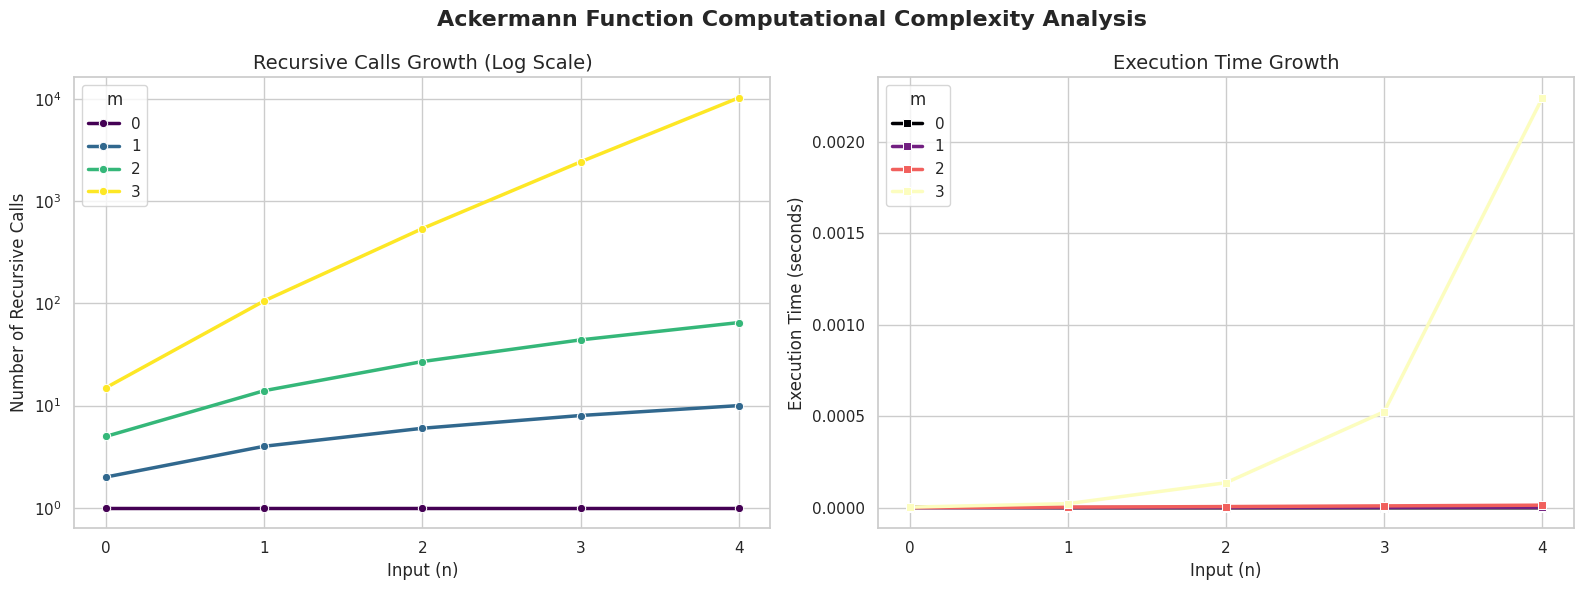

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Create a multi-plot layout
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plotting Recursive Calls vs n for different m values
sns.lineplot(
    ax=axes[0],
    data=df_metrics,
    x='n',
    y='calls',
    hue='m',
    marker='o',
    palette='viridis',
    linewidth=2.5
)
axes[0].set_title('Recursive Calls Growth (Log Scale)', fontsize=14)
axes[0].set_xlabel('Input (n)', fontsize=12)
axes[0].set_ylabel('Number of Recursive Calls', fontsize=12)
axes[0].set_yscale('log')  # Log scale highlights exponential behavior beautifully
axes[0].set_xticks(range(5))

# 2. Plotting Execution Time vs n for different m values
sns.lineplot(
    ax=axes[1],
    data=df_metrics,
    x='n',
    y='time_seconds',
    hue='m',
    marker='s',
    palette='magma',
    linewidth=2.5
)
axes[1].set_title('Execution Time Growth', fontsize=14)
axes[1].set_xlabel('Input (n)', fontsize=12)
axes[1].set_ylabel('Execution Time (seconds)', fontsize=12)
axes[1].set_xticks(range(5))

plt.suptitle('Ackermann Function Computational Complexity Analysis', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

## 4. Interactive Analyzer Dashboard

To make this exploration user-friendly, we will create an interactive dashboard using `ipywidgets`. This dashboard allows you to select values for $m$ and $n$, evaluate the function, view runtime statistics, and obtain a conceptual trace of how the recursive calls branch.

In [4]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Input widgets for m and n
m_slider = widgets.IntSlider(value=2, min=0, max=3, step=1, description='Value of m:')
n_slider = widgets.IntSlider(value=3, min=0, max=5, step=1, description='Value of n:')
calculate_btn = widgets.Button(description='Calculate & Analyze', button_style='primary', icon='calculator')
output_area = widgets.Output()

def generate_trace_explanation(m, n):
    """
    Generates a helpful, educational walkthrough explanation
    of how the recursion starts for the chosen (m, n).
    """
    explanation = [f"### Recursion Walkthrough for $A({m}, {n})$:"]
    if m == 0:
        explanation.append(f"- Since $m=0$, we immediately apply the Base Case 1: $A(0, n) = n + 1$.")
        explanation.append(f"- **Result:** $A(0, {n}) = {n} + 1 = {n+1}$.")
    elif m > 0 and n == 0:
        explanation.append(f"- Since $n=0$ and $m={m} > 0$, we apply Case 2: $A(m, 0) = A(m-1, 1)$.")
        explanation.append(f"- This reduces our problem of solving $A({m}, 0)$ to solving **$A({m-1}, 1)$**.")
    else:
        explanation.append(f"- Since both $m={m} > 0$ and $n={n} > 0$, we apply the complex nested recursion Case 3: $A(m, n) = A(m-1, A(m, n-1))$.")
        explanation.append(f"- First, we must compute the inner value: **$A({m}, {n-1})$**.")
        explanation.append(f"- Then, we pass that resulting integer as the second argument to $A({m-1}, \dots)$.")
    return "\n".join(explanation)

def on_click_calculate(b):
    with output_area:
        clear_output()
        m_val = m_slider.value
        n_val = n_slider.value

        # Warning if inputs get dangerously high (e.g. m=3, n=5 gets heavy, m>=4 can crash typical runtimes)
        if m_val == 3 and n_val > 4:
            print("⚠️ Warning: High input selected. Computing...")

        res, stats = evaluate_ackermann(m_val, n_val)

        # Render metrics nicely with HTML
        metrics_html = f"""
        <div style="padding: 15px; border-radius: 8px; background-color: #f7f9fa; border-left: 5px solid #007bff; margin-top: 15px;">
            <h3 style="margin-top:0; color:#007bff;">Calculation Successful!</h3>
            <p style="font-size: 16px;"><b>Mathematical Result:</b> <span style="font-size: 18px; color: #d9534f; font-weight: bold;">A({m_val}, {n_val}) = {res}</span></p>
            <table style="width: 100%; border-collapse: collapse; margin-top: 10px;">
                <tr style="border-bottom: 1px solid #ddd;">
                    <th style="text-align: left; padding: 8px;">Metric</th>
                    <th style="text-align: left; padding: 8px;">Value</th>
                </tr>
                <tr>
                    <td style="padding: 8px;">Total Recursive Calls</td>
                    <td style="padding: 8px; font-weight: bold;">{stats['calls']:,}</td>
                </tr>
                <tr>
                    <td style="padding: 8px;">Peak Recursion Stack Depth</td>
                    <td style="padding: 8px; font-weight: bold;">{stats['max_depth']:,}</td>
                </tr>
                <tr>
                    <td style="padding: 8px;">Execution Duration</td>
                    <td style="padding: 8px; font-weight: bold; color: #5cb85c;">{stats['time_seconds']:.6f} seconds</td>
                </tr>
            </table>
        </div>
        """
        display(HTML(metrics_html))

        # Display the theoretical trace breakdown
        display(HTML("<br>"))
        print(generate_trace_explanation(m_val, n_val))

# Bind the button trigger
calculate_btn.on_click(on_click_calculate)

# Display the components together
layout = widgets.VBox([
    widgets.HTML("<h3>Ackermann Dynamic Dashboard Panel</h3>"),
    m_slider,
    n_slider,
    calculate_btn,
    output_area
])

display(layout)

<>:25: SyntaxWarning: invalid escape sequence '\d'
<>:25: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_4185/2777080193.py:25: SyntaxWarning: invalid escape sequence '\d'
  explanation.append(f"- Then, we pass that resulting integer as the second argument to $A({m-1}, \dots)$.")


## 5. Demystifying the Ackermann Function: Why does it explode?

To make this intuitive, let's look at what the parameter $m$ actually controls. You can think of $m$ as choosing the **arithmetic operator**, and $n$ as the input to that operator.

### The Intuitive Breakdown of $m$:

*   **When $m = 0$ (Addition):**
    $$A(0, n) = n + 1$$
    This is just incrementing by $1$. Very slow, linear growth.

*   **When $m = 1$ (Multiplication-like):**
    $$A(1, n) = n + 2$$
    Through recursion, $m=1$ repeatedly adds $1$ to itself. It acts like basic addition/multiplication behavior.

*   **When $m = 2$ (Exponentiation-like):**
    $$A(2, n) = 2n + 3$$
    Now, we are repeatedly doubling. This represents linear/exponential multipliers.

*   **When $m = 3$ (Power Tower / Tetration):**
    $$A(3, n) = 2^{(n+3)} - 3$$
    Here, we are calculating powers of $2$. For example:
    *   $A(3, 1) = 2^4 - 3 = 13$
    *   $A(3, 2) = 2^5 - 3 = 29$
    *   $A(3, 3) = 2^6 - 3 = 61$
    *   $A(3, 4) = 2^7 - 3 = 125$

*   **When $m = 4$ (Hyper-Tetration / Pentation):**
    $$A(4, n) = \underbrace{2^{2^{2^{\cdot^{\cdot^{2}}}}}}_\text{n + 3 times} - 3$$
    This is a **tower of powers of 2**.
    *   $A(4, 0) = A(3, 1) = 13$
    *   $A(4, 1) = A(3, 13) = 2^{16} - 3 = 65,533$
    *   $A(4, 2) = A(3, 65533) = 2^{65536} - 3$
    
    *Note: $2^{65536}$ is a number with **19,729 decimal digits**! This is why $A(4, 2)$ cannot be computed by any modern computer—it would run out of memory and time instantly. This is what we mean by "hyper-exponential" growth.*

---

## 6. What does this have to do with Computability?

1.  **Primitive Recursive Functions:** These are functions you can build using simple `for` loops where the number of iterations is known before the loop starts (like `for i in range(10):`). Almost all everyday mathematical functions (addition, multiplication, powers, factorials) are primitive recursive.
2.  **The Ackermann Limit:** Because $A(m, n)$ grows faster than any single nested structure of `for` loops can handle, it cannot be written using only simple bounded loops. It **requires** a `while` loop or unbounded recursion.
3.  **Computable:** Even though it grows ridiculously fast, it is still **computable** (or recursive) because if you give it enough time, memory, and stack depth, the rules will eventually terminate and give you a precise answer.